# **Diabetes Prediction – Data Preprocessing**
Dataset: `iammustafatz/diabetes-prediction-dataset` (Kaggle)

**Target:** `diabetes` (0 = No, 1 = Yes)

**Steps:** Load -> Understand -> Missing Values -> Inconsistency -> Duplicates -> Datatypes -> Outliers -> Encoding -> Scaling -> Save

# **Import Libraries**

In [3]:
import warnings
warnings.filterwarnings('ignore')

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

# **Load Dataset**

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("Path to dataset files:", path)

csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv_file)
df_raw = df.copy()      # untouched copy = data BEFORE preprocessing

# Standardize column names first (e.g. 'HbA1c_level' -> 'hba1c_level') so the rest of the notebook is consistent
df.columns = df.columns.str.strip().str.lower()
df.head()

Path to dataset files: C:\Users\adnan\.cache\kagglehub\datasets\iammustafatz\diabetes-prediction-dataset\versions\1


,gender,age,hypertension,heart_disease,smoking_history,bmi,hba1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


# **Understand the Data**

In [5]:
print("Rows, Columns:", df.shape)
df.info()

Rows, Columns: (100000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   hba1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [6]:
df.describe()

,age,hypertension,heart_disease,bmi,hba1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [7]:
df.describe(include='object')

,gender,smoking_history
count,100000,100000
unique,3,6
top,Female,No Info
freq,58552,35816


### **Visualization – raw data overview**

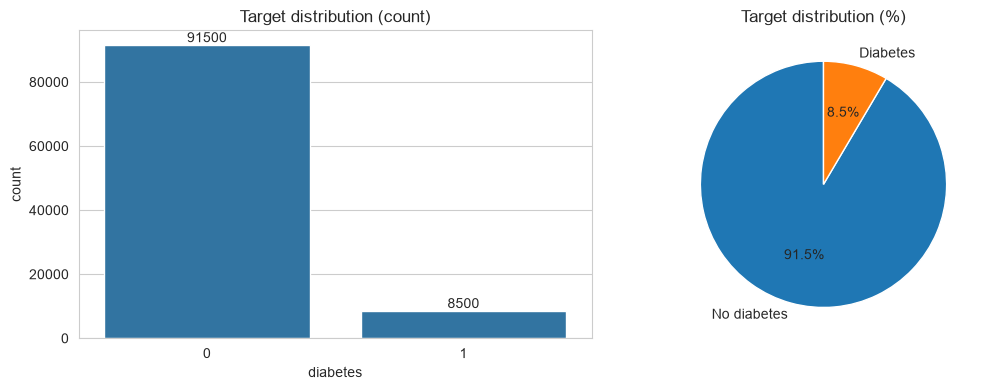

In [8]:
num_cols = ['age', 'bmi', 'hba1c_level', 'blood_glucose_level']
cat_cols = ['gender', 'smoking_history']
bin_cols = ['hypertension', 'heart_disease']

# Target distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df['diabetes'].value_counts()
sns.countplot(x='diabetes', data=df, ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                   ha='center', va='bottom')
ax[0].set_title('Target distribution (count)')
ax[1].pie(counts, labels=['No diabetes', 'Diabetes'], autopct='%1.1f%%', startangle=90)
ax[1].set_title('Target distribution (%)')
plt.tight_layout(); plt.show()

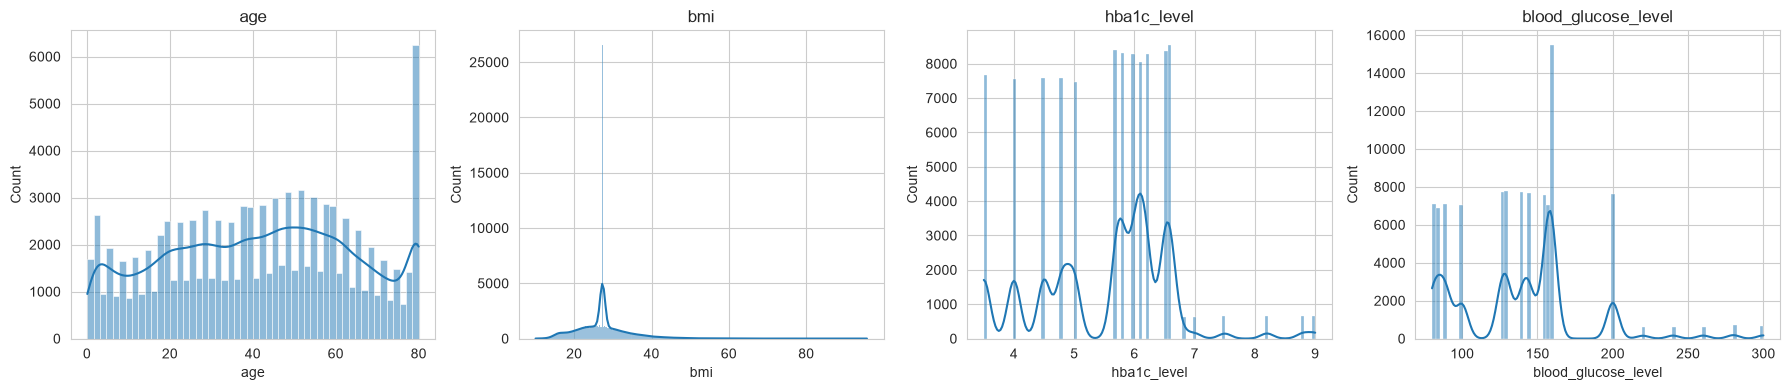

In [9]:
# Numerical features – raw distributions
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

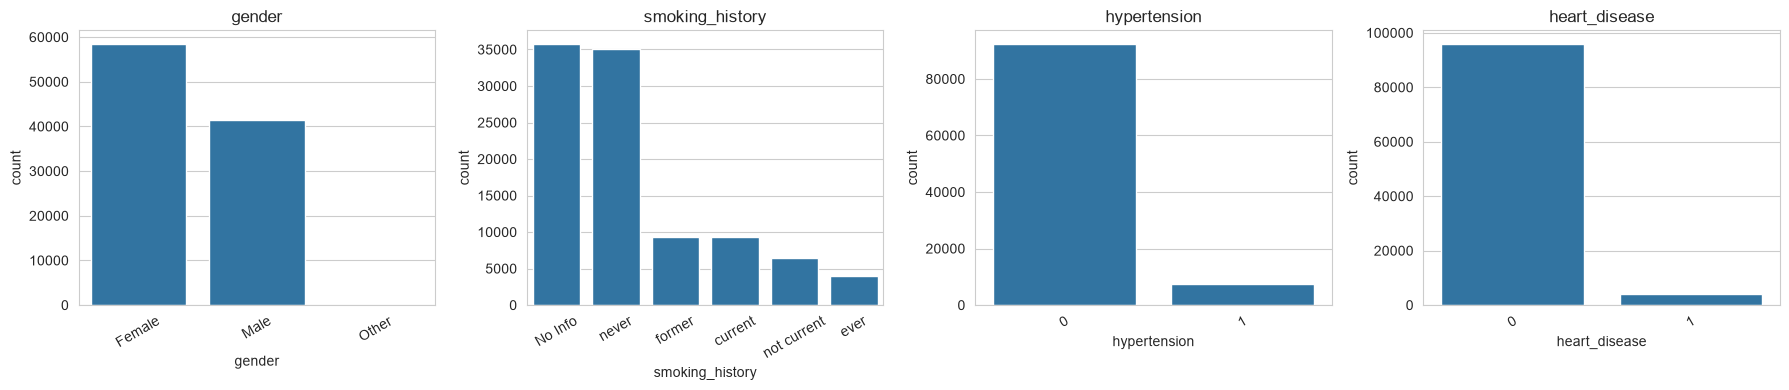

In [10]:
# Categorical + binary features – raw counts
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols + bin_cols):
    sns.countplot(x=col, data=df, ax=ax, order=df[col].value_counts().index)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

# **DataCleaning**

## **Missing Values**

In [11]:
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_%': (df.isnull().sum() / len(df) * 100).round(3)
}).sort_values('missing_count', ascending=False)
missing

,missing_count,missing_%
gender,0,0.0
age,0,0.0
hypertension,0,0.0
heart_disease,0,0.0
smoking_history,0,0.0
bmi,0,0.0
hba1c_level,0,0.0
blood_glucose_level,0,0.0
diabetes,0,0.0


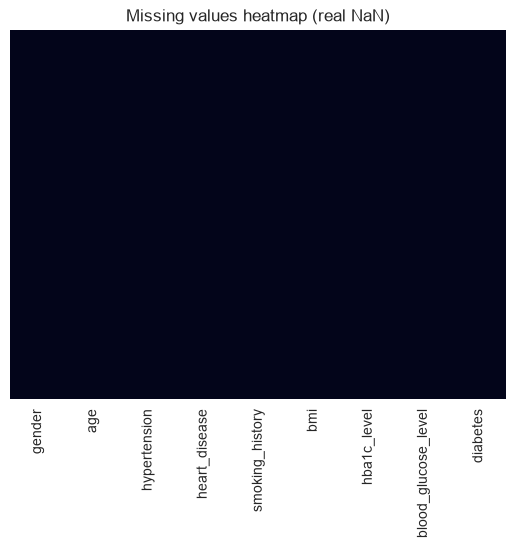

In [12]:
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing values heatmap (real NaN)')
plt.show()

`isnull()` shows **0 nulls**, but missing data can hide behind a *placeholder label*. Check every categorical column.

In [13]:
for col in df.select_dtypes(include='object').columns:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), '\n')

--- gender ---
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64 

--- smoking_history ---
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64 



`smoking_history` contains `No Info` - this is hidden missing data. Convert it to NaN so we can see how big the problem really is.

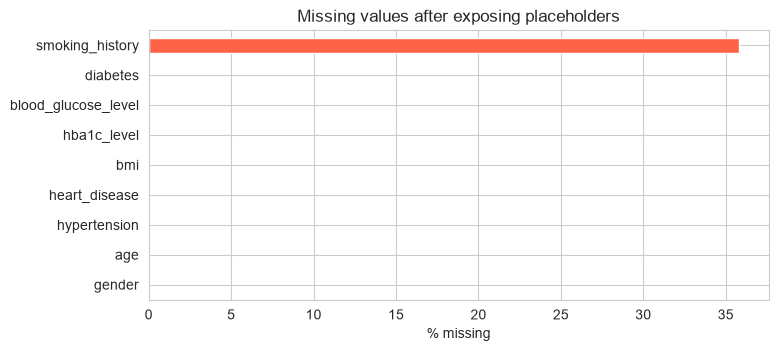

smoking_history missing: 35816 rows (35.82%)


In [14]:
df['smoking_history'] = df['smoking_history'].replace('No Info', np.nan)

pct = df.isnull().mean() * 100
plt.figure(figsize=(8, 3.5))
pct.sort_values().plot(kind='barh', color='tomato')
plt.xlabel('% missing'); plt.title('Missing values after exposing placeholders')
plt.show()
print(f"smoking_history missing: {df['smoking_history'].isnull().sum()} rows ({pct['smoking_history']:.2f}%)")

### **Handle Missing Values**

A large share of rows is missing, so dropping them would lose too much data, and filling with the mode would invent smoking habits for those patients. The safest option is to keep them as their own category: `unknown`.

In [15]:
df['smoking_history'] = df['smoking_history'].fillna('unknown')

# safety net for the remaining columns (numeric -> median, categorical -> mode)
for c in df.columns:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median() if df[c].dtype != 'object' else df[c].mode()[0])

print("Total nulls now:", df.isnull().sum().sum())

Total nulls now: 0


## **Data Inconsistency**

### **1. Inconsistent format (text case, extra spaces)**

Column names were already standardized at load time. Now do the same for the text values, so `Male`, `male ` and `MALE` cannot become three different categories.

In [16]:
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].str.strip().str.lower()

for c in ['gender', 'smoking_history']:
    print(c, '->', sorted(df[c].dropna().unique()))

gender -> ['female', 'male', 'other']
smoking_history -> ['current', 'ever', 'former', 'never', 'not current', 'unknown']


### **2. Rare / unusable category – `gender`**

In [17]:
print(df['gender'].value_counts())

gender
female    58552
male      41430
other        18
Name: count, dtype: int64


In [18]:
print("Rows with gender = other:", (df['gender'] == 'other').sum())
df = df[df['gender'] != 'other'].reset_index(drop=True)
print(df['gender'].value_counts())

Rows with gender = other: 18
gender
female    58552
male      41430
Name: count, dtype: int64


### **3. Inconsistent naming – `smoking_history`**

`not current` and `former` both mean *used to smoke, doesn't now*, so they are merged.

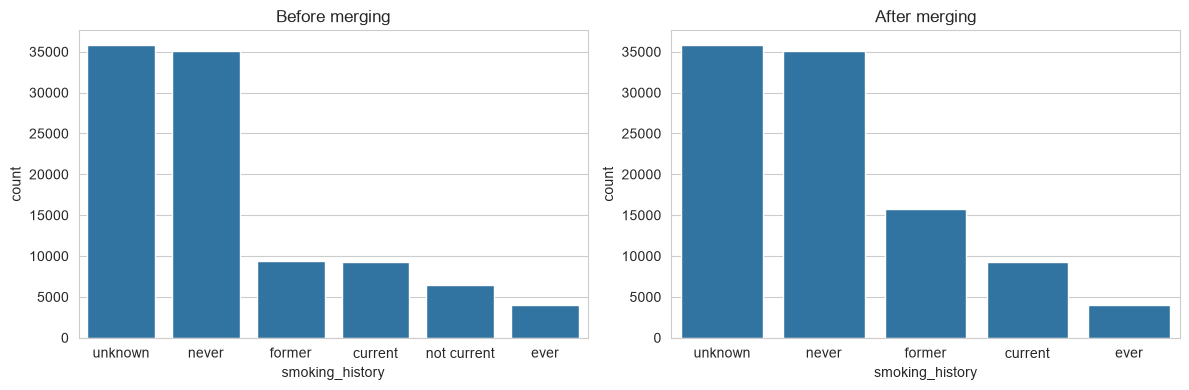

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='smoking_history', data=df, ax=ax[0], order=df['smoking_history'].value_counts().index)
ax[0].set_title('Before merging')

df['smoking_history'] = df['smoking_history'].replace({'not current': 'former'})

sns.countplot(x='smoking_history', data=df, ax=ax[1], order=df['smoking_history'].value_counts().index)
ax[1].set_title('After merging')
plt.tight_layout(); plt.show()

### **4. Invalid / contradictory values**

In [20]:
invalid = pd.Series({
    'age <= 0 or > 120'        : ((df['age'] <= 0) | (df['age'] > 120)).sum(),
    'bmi <= 0'                 : (df['bmi'] <= 0).sum(),
    'hba1c_level <= 0'         : (df['hba1c_level'] <= 0).sum(),
    'blood_glucose_level <= 0' : (df['blood_glucose_level'] <= 0).sum(),
    'hypertension not in 0/1'  : (~df['hypertension'].isin([0, 1])).sum(),
    'heart_disease not in 0/1' : (~df['heart_disease'].isin([0, 1])).sum(),
    'diabetes not in 0/1'      : (~df['diabetes'].isin([0, 1])).sum(),
}, name='invalid_rows')
invalid

age <= 0 or > 120           0
bmi <= 0                    0
hba1c_level <= 0            0
blood_glucose_level <= 0    0
hypertension not in 0/1     0
heart_disease not in 0/1    0
diabetes not in 0/1         0
Name: invalid_rows, dtype: int64

In [21]:
# Remove any invalid rows found (count is 0 if the data is clean)
mask = (
    (df['age'] > 0) & (df['age'] <= 120) &
    (df['bmi'] > 0) & (df['hba1c_level'] > 0) & (df['blood_glucose_level'] > 0)
)
print("Rows removed:", (~mask).sum())
df = df[mask].reset_index(drop=True)

Rows removed: 0


### **5. Duplicate rows**

Duplicate rows: 3952 (3.95%)


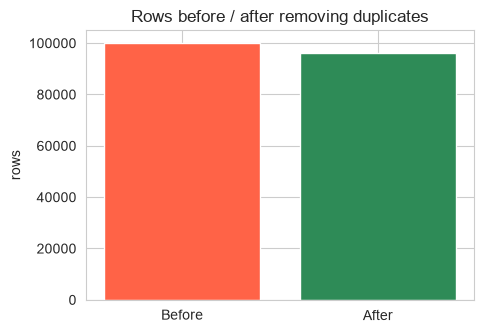

New shape: (96030, 9)


In [22]:
n_dup = df.duplicated().sum()
print(f"Duplicate rows: {n_dup} ({n_dup/len(df)*100:.2f}%)")

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

plt.figure(figsize=(5, 3.5))
plt.bar(['Before', 'After'], [before, len(df)], color=['tomato', 'seagreen'])
plt.title('Rows before / after removing duplicates'); plt.ylabel('rows')
plt.show()
print("New shape:", df.shape)

## **Handle DataType**

In [23]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
hba1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [24]:
# age stays float (infants like 0.08 exist). Flags -> int8, text -> category
df[bin_cols + ['diabetes']] = df[bin_cols + ['diabetes']].astype('int8')
df['blood_glucose_level'] = df['blood_glucose_level'].astype('int32')
df[cat_cols] = df[cat_cols].astype('category')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96030 entries, 0 to 96029
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   gender               96030 non-null  category
 1   age                  96030 non-null  float64 
 2   hypertension         96030 non-null  int8    
 3   heart_disease        96030 non-null  int8    
 4   smoking_history      96030 non-null  category
 5   bmi                  96030 non-null  float64 
 6   hba1c_level          96030 non-null  float64 
 7   blood_glucose_level  96030 non-null  int32   
 8   diabetes             96030 non-null  int8    
dtypes: category(2), float64(3), int32(1), int8(3)
memory usage: 3.0 MB


### **Visualization – cleaned data vs target**

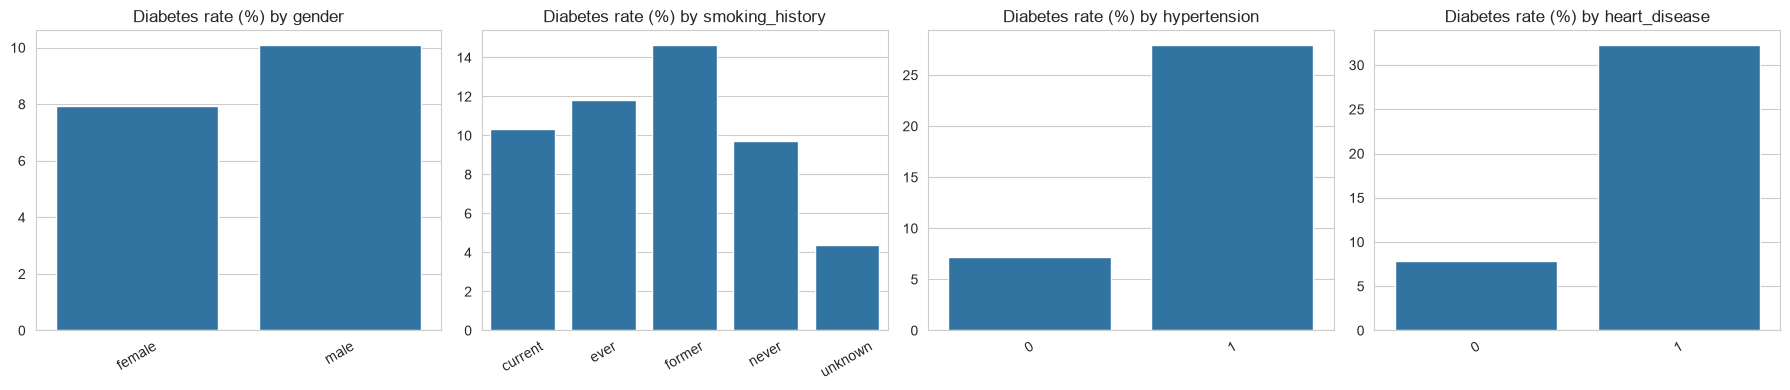

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols + bin_cols):
    rate = df.groupby(col, observed=True)['diabetes'].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f'Diabetes rate (%) by {col}')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

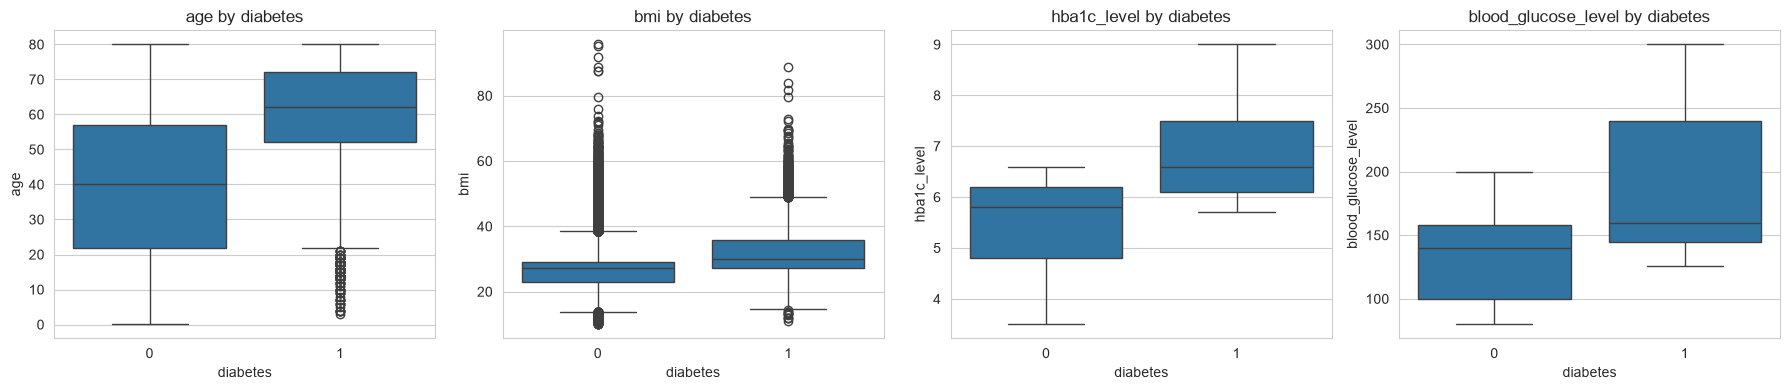

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='diabetes', y=col, data=df, ax=ax)
    ax.set_title(f'{col} by diabetes')
plt.tight_layout(); plt.show()

# **Outlier**

In [27]:
df[num_cols].describe()

,age,bmi,hba1c_level,blood_glucose_level
count,96030.000000,96030.000000,96030.000000,96030.000000
mean,41.779738,27.321452,5.532951,138.223586
std,22.459205,6.771263,1.073238,40.917123
min,0.080000,10.010000,3.500000,80.000000
25%,24.000000,23.400000,4.800000,100.000000
50%,43.000000,27.320000,5.800000,140.000000
75%,59.000000,29.860000,6.200000,159.000000
max,80.000000,95.690000,9.000000,300.000000


In [28]:
df[num_cols].skew().rename('skewness')

age                   -0.062489
bmi                    1.023422
hba1c_level           -0.054171
blood_glucose_level    0.836934
Name: skewness, dtype: float64

### **Detect – box plots**

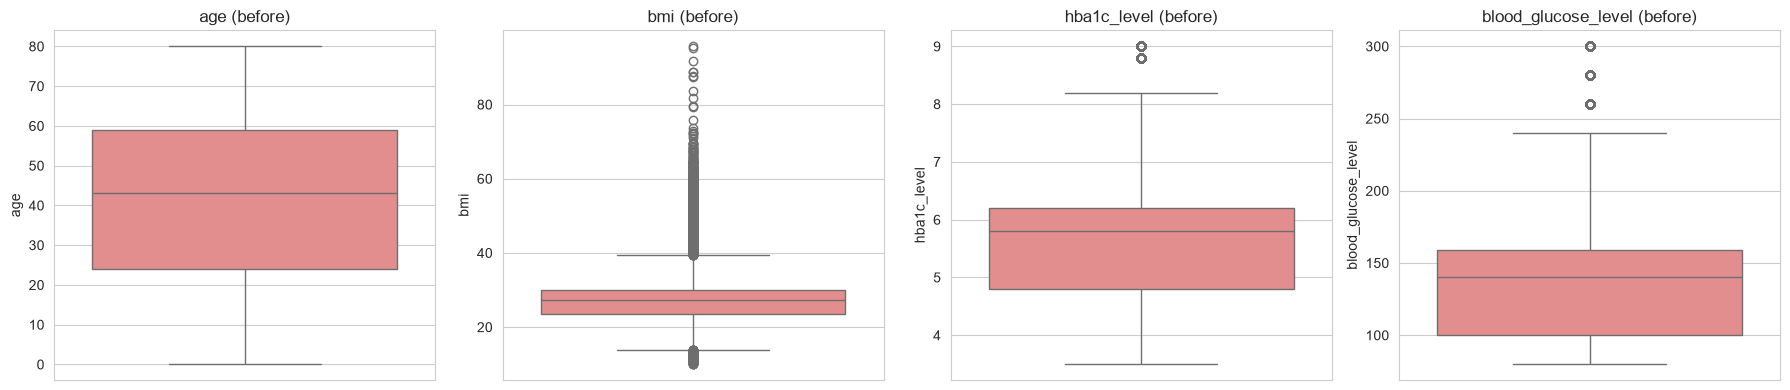

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightcoral')
    ax.set_title(f'{col} (before)')
plt.tight_layout(); plt.show()

### **IQR Method**

In [30]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in num_cols:
    lo, hi = iqr_bounds(df[col])
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 2), round(hi, 2), n, round(n / len(df) * 100, 2)])
iqr_table = pd.DataFrame(rows, columns=['column', 'lower', 'upper', 'n_outliers', '%'])
iqr_table

,column,lower,upper,n_outliers,%
0,age,-28.50,111.50,0,0.00
1,bmi,13.71,39.55,5354,5.58
2,hba1c_level,2.70,8.30,1312,1.37
3,blood_glucose_level,11.50,247.50,2031,2.11


### **Z-Score Method**

In [31]:
from scipy import stats
pd.DataFrame({
    'column': num_cols,
    'n_outliers (|z|>3)': [(np.abs(stats.zscore(df[c])) > 3).sum() for c in num_cols]
})

,column,n_outliers (|z|>3)
0,age,0
1,bmi,1211
2,hba1c_level,1312
3,blood_glucose_level,1397


### **Handle Outliers**

In medical data an extreme value is usually a **real patient**, so deleting rows would remove genuine (often diabetic) cases. We decide per column:

| Column | Decision | Reason |
|---|---|---|
| `bmi` | **Cap** at IQR bounds | very high BMI values are rare and extend far beyond the bulk of the data |
| `age` | Keep | all values are valid ages |
| `hba1c_level` | Keep | valid clinical range, strong predictor |
| `blood_glucose_level` | Keep | valid clinical range, strong predictor |



In [32]:
bmi_lo, bmi_hi = iqr_bounds(df['bmi'])
print(f"BMI cap range: {bmi_lo:.2f} - {bmi_hi:.2f}")

bmi_before = df['bmi'].copy()
df['bmi'] = df['bmi'].clip(bmi_lo, bmi_hi)

BMI cap range: 13.71 - 39.55


### **Visualization – before vs after capping**

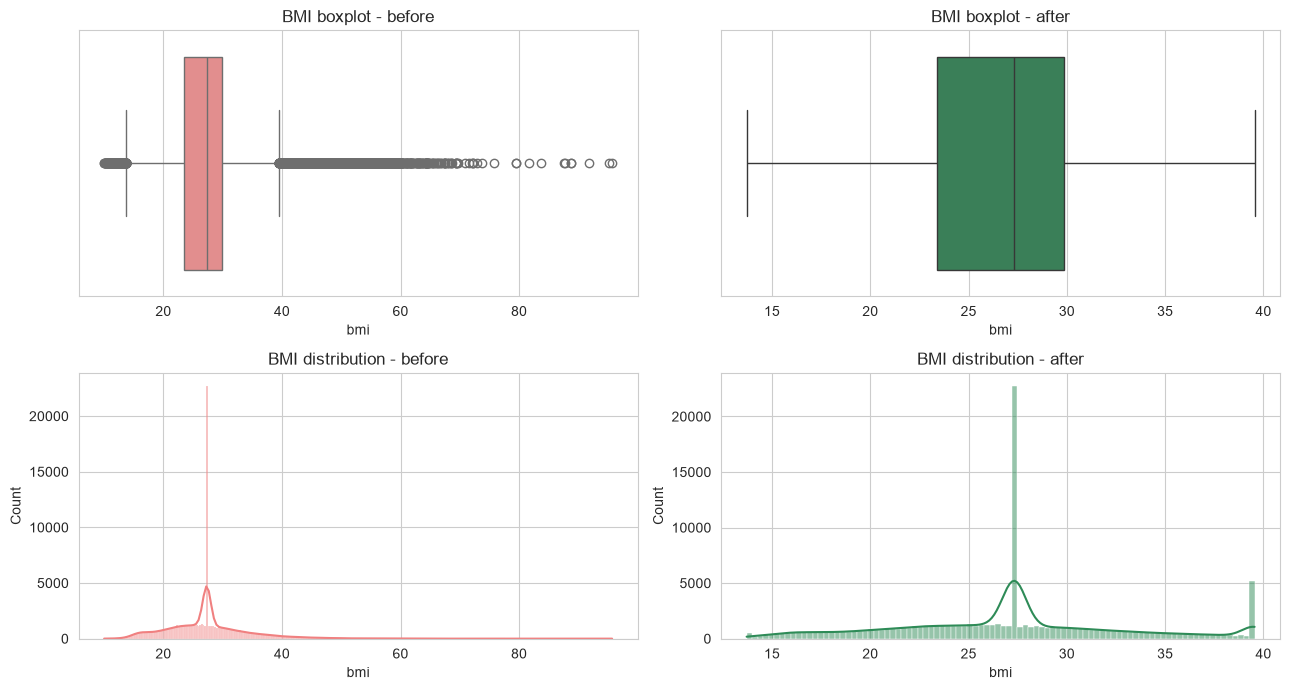

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
sns.boxplot(x=bmi_before, ax=axes[0, 0], color='lightcoral');   axes[0, 0].set_title('BMI boxplot - before')
sns.boxplot(x=df['bmi'], ax=axes[0, 1], color='seagreen'); axes[0, 1].set_title('BMI boxplot - after')
sns.histplot(bmi_before, kde=True, ax=axes[1, 0], color='lightcoral');   axes[1, 0].set_title('BMI distribution - before')
sns.histplot(df['bmi'], kde=True, ax=axes[1, 1], color='seagreen'); axes[1, 1].set_title('BMI distribution - after')
plt.tight_layout(); plt.show()

# **Data Encoding**

| Column | Type | Encoding |
|---|---|---|
| `gender` | nominal (2 values) | One-Hot (`drop='first'`) -> one 0/1 column `gender_male` |
| `smoking_history` | nominal (no real order) | One-Hot (`drop='first'`) |
| `hypertension`, `heart_disease` | already 0/1 | no change |

One-Hot is used instead of Label Encoding because these categories have **no natural order**, and a numeric label would wrongly tell the model that `never` < `former` < `current`.

In [34]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
ohe.fit(df[cat_cols])

print("Categories learned:", dict(zip(cat_cols, ohe.categories_)))
print("Baseline (dropped) category:", {c: cats[0] for c, cats in zip(cat_cols, ohe.categories_)})
print("New columns:", ohe.get_feature_names_out().tolist())

Categories learned: {'gender': array(['female', 'male'], dtype=object), 'smoking_history': array(['current', 'ever', 'former', 'never', 'unknown'], dtype=object)}
Baseline (dropped) category: {'gender': 'female', 'smoking_history': 'current'}
New columns: ['gender_male', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_unknown']


# **Scalization – Standard Scaler**

`age`, `bmi`, `hba1c_level` and `blood_glucose_level` are on very different scales (e.g. glucose in the hundreds, HbA1c in single digits). Standardizing puts them on the same scale (mean 0, std 1), which Logistic Regression, SVM, KNN and Neural Networks need. Binary and one-hot columns are not scaled.

# **Final Preprocessing Pipeline**

Encoding + scaling in one `ColumnTransformer` applied to the cleaned dataset.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols),
    ],
    verbose_feature_names_out=False
)
preprocessor.set_output(transform='pandas')

X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_processed = preprocessor.fit_transform(X)

print("Before:", X.shape, "| After:", X_processed.shape)
X_processed.head()

Before: (96030, 8) | After: (96030, 11)


,age,bmi,hba1c_level,blood_glucose_level,hypertension,heart_disease,gender_male,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_unknown
0,1.701773,-0.310755,0.994239,0.043415,0,1,0.0,0.0,0.0,1.0,0.0
1,0.544112,0.048864,0.994239,-1.422971,0,0,0.0,0.0,0.0,0.0,1.0
2,-0.613548,0.048864,0.155650,0.483331,0,0,1.0,0.0,0.0,1.0,0.0
3,-0.257345,-0.604528,-0.496585,0.410012,0,0,0.0,0.0,0.0,0.0,0.0
4,1.523671,-1.163373,-0.682938,0.410012,1,1,1.0,0.0,0.0,0.0,0.0


In [36]:
print("Nulls:", X_processed.isnull().sum().sum())
print("Columns:", X_processed.columns.tolist())
X_processed.dtypes

Nulls: 0
Columns: ['age', 'bmi', 'hba1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease', 'gender_male', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_unknown']


age                        float64
bmi                        float64
hba1c_level                float64
blood_glucose_level        float64
hypertension                  int8
heart_disease                 int8
gender_male                float64
smoking_history_ever       float64
smoking_history_former     float64
smoking_history_never      float64
smoking_history_unknown    float64
dtype: object

### **Visualization – scaling & encoding result**

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(num_cols):
    sns.histplot(X[col], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{col} - before scaling')
    sns.histplot(X_processed[col], kde=True, ax=axes[1, i], color='seagreen')
    axes[1, i].set_title(f'{col} - after scaling')
plt.tight_layout(); plt.show()

In [ ]:
# Mean ~ 0 and std ~ 1 check
X_processed[num_cols].agg(['mean', 'std']).round(3)

In [ ]:
# Encoded columns
enc_cols = [c for c in X_processed.columns if c not in num_cols]
X_processed[enc_cols].sum().sort_values().plot(kind='barh', figsize=(7, 4), color='slateblue')
plt.title('Count of 1s in each encoded / binary column')
plt.show()

### **Correlation of final features with target**

In [ ]:
final_df = X_processed.assign(diabetes=y.values)

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(final_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[0], cbar=False)
ax[0].set_title('Correlation matrix (processed data)')

final_df.corr()['diabetes'].drop('diabetes').sort_values().plot(kind='barh', ax=ax[1], color='teal')
ax[1].set_title('Correlation with diabetes')
plt.tight_layout(); plt.show()

# **Before vs After Preprocessing**

In [ ]:
final_df = X_processed.assign(diabetes=y.values)

summary = pd.DataFrame({
    'Before preprocessing': [df_raw.shape[0], df_raw.shape[1], df_raw.isnull().sum().sum(),
                             df_raw.duplicated().sum(), df_raw['smoking_history'].eq('No Info').sum(),
                             int(df_raw.select_dtypes(include='object').shape[1])],
    'After preprocessing' : [final_df.shape[0], final_df.shape[1], final_df.isnull().sum().sum(),
                             final_df.duplicated().sum(), 0,
                             int(final_df.select_dtypes(include='object').shape[1])],
}, index=['Rows', 'Columns', 'Null values', 'Duplicate rows', "'No Info' placeholders", 'Text (object) columns'])
summary

In [ ]:
print("BEFORE (raw data):")
display(df_raw.head())
print("\nAFTER (preprocessed data):")
display(final_df.head())

# **Save & Download Both Files (CSV)**

- `diabetes_before_preprocessing.csv` -> raw data exactly as downloaded
- `diabetes_after_preprocessing.csv` -> cleaned, encoded and scaled data

In [ ]:
before_csv = 'diabetes_before_preprocessing.csv'
after_csv  = 'diabetes_after_preprocessing.csv'

df_raw.to_csv(before_csv, index=False)
final_df.to_csv(after_csv, index=False)

print("Saved:", os.path.abspath(before_csv), df_raw.shape)
print("Saved:", os.path.abspath(after_csv),  final_df.shape)

In [ ]:
# Download both files
try:
    from google.colab import files
    files.download(before_csv)
    files.download(after_csv)
except ImportError:
    print("Not running in Colab - both files are saved in:", os.getcwd())